In [1]:
# Import necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
# Load dataset
df = pd.read_csv("NASA TurboFan Engine.csv")

# Display dataset
print(df.shape)
print(df.head())

# Sort data by engine and cycle
df = df.sort_values(['unit', 'cycle']).reset_index(drop=True)

# Select sensor columns
sensor_cols = [f'sensor{i}' for i in range(1, 22)]

# Handle missing values
df[sensor_cols] = df.groupby('unit')[sensor_cols].transform(
    lambda x: x.ffill().bfill()
)

# Split engines into training, validation and testing
units = sorted(df['unit'].unique())

train_units = units[:70]
val_units = units[70:85]
test_units = units[85:]

train_df = df[df['unit'].isin(train_units)].copy()
val_df = df[df['unit'].isin(val_units)].copy()
test_df = df[df['unit'].isin(test_units)].copy()

# Extract sensor data and labels
X_train_raw = train_df[sensor_cols].values
y_train = train_df['Fault_Label'].values

X_val_raw = val_df[sensor_cols].values
y_val = val_df['Fault_Label'].values

X_test_raw = test_df[sensor_cols].values
y_test = test_df['Fault_Label'].values

# Normalize sensor readings using healthy training data
scaler = MinMaxScaler()

scaler.fit(X_train_raw[y_train == 0])

X_train = scaler.transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

(20631, 28)
   unit  cycle  setting1  setting2  setting3  sensor1  sensor2  sensor3  \
0     1      1   -0.0007   -0.0004     100.0   518.67   641.82  1589.70   
1     1      2    0.0019   -0.0003     100.0   518.67   642.15  1591.82   
2     1      3   -0.0043    0.0003     100.0   518.67   642.35  1587.99   
3     1      4    0.0007    0.0000     100.0   518.67   642.35  1582.79   
4     1      5   -0.0019   -0.0002     100.0   518.67   642.37  1582.85   

   sensor4  sensor5  ...  sensor14  sensor15  sensor16  sensor17  sensor18  \
0  1400.60    14.62  ...   8138.62    8.4195      0.03       392      2388   
1  1403.14    14.62  ...   8131.49    8.4318      0.03       392      2388   
2  1404.20    14.62  ...   8133.23    8.4178      0.03       390      2388   
3  1401.87    14.62  ...   8133.83    8.3682      0.03       392      2388   
4  1406.22    14.62  ...   8133.80    8.4294      0.03       393      2388   

   sensor19  sensor20  sensor21  RUL  Fault_Label  
0     100.0     

In [6]:
# Create sequences separately for each engine
TIME_STEPS = 30

def create_sequences(data, labels, units, time_steps):

    sequences = []
    sequence_labels = []

    start = 0

    for unit in sorted(np.unique(units)):

        indices = np.where(units == unit)[0]

        engine_data = data[indices]
        engine_labels = labels[indices]

        for i in range(len(engine_data) - time_steps + 1):

            sequences.append(
                engine_data[i:i + time_steps]
            )

            # Label of the last cycle in the window
            sequence_labels.append(
                engine_labels[i + time_steps - 1]
            )

    return np.array(sequences), np.array(sequence_labels)


# Create sequences
X_train_seq, y_train_seq = create_sequences(
    X_train, y_train,
    train_df['unit'].values, TIME_STEPS
)

X_val_seq, y_val_seq = create_sequences(
    X_val, y_val,
    val_df['unit'].values, TIME_STEPS
)

X_test_seq, y_test_seq = create_sequences(
    X_test, y_test,
    test_df['unit'].values, TIME_STEPS
)

# Select only healthy sequences for training
X_train_normal = X_train_seq[
    y_train_seq == 0
]

# Select normal validation sequences
X_val_normal = X_val_seq[
    y_val_seq == 0
]

print("Normal training sequences:", X_train_normal.shape)
print("Validation sequences:", X_val_seq.shape)
print("Testing sequences:", X_test_seq.shape)


Normal training sequences: (9930, 30, 21)
Validation sequences: (2775, 30, 21)
Testing sequences: (2856, 30, 21)


In [7]:
# Define LSTM Autoencoder
model = keras.Sequential([

    # Encoder
    layers.Input(shape=(TIME_STEPS, 21)),

    layers.LSTM(64, activation='tanh',
                return_sequences=False),

    # Latent representation
    layers.RepeatVector(TIME_STEPS),

    # Decoder
    layers.LSTM(64, activation='tanh',
                return_sequences=True),

    layers.TimeDistributed(
        layers.Dense(21)
    )
])

# Compile model
model.compile(
    optimizer='adam',
    loss='mse'
)

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 64)                  │          22,016 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector (RepeatVector)         │ (None, 30, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 30, 64)              │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 30, 21)              │           1,365 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 56,405 (220.33 KB)

 Trainable params: 56,405 (220.33 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Train autoencoder using only normal sequences
history = model.fit(
    X_train_normal,
    X_train_normal,
    epochs=20,
    batch_size=64,
    validation_data=(X_val_normal, X_val_normal),
    shuffle=True
)

Epoch 1/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 36s 123ms/step - loss: 0.0174 - val_loss: 0.0064
Epoch 2/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 16s 104ms/step - loss: 0.0061 - val_loss: 0.0060
Epoch 3/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 16s 103ms/step - loss: 0.0059 - val_loss: 0.0059
Epoch 4/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 16s 100ms/step - loss: 0.0059 - val_loss: 0.0059
Epoch 5/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 18s 117ms/step - loss: 0.0058 - val_loss: 0.0058
Epoch 6/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 19s 123ms/step - loss: 0.0058 - val_loss: 0.0058
Epoch 7/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 18s 114ms/step - loss: 0.0058 - val_loss: 0.0059
Epoch 8/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 17s 105ms/step - loss: 0.0058 - val_loss: 0.0059
Epoch 9/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 15s 97ms/step - loss: 0.0058 - val_loss: 0.0058
Epoch 10/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 15s 95ms/step - loss: 0.0058 - val_loss: 0.0058
Epoch 11/20
156/156 ━━━━━━━━━━━━━━━━━━━━ 16s 103ms/step - loss: 0.0058 - val_loss: 0.0058
Epoch 12/20
156/156 ━

In [17]:
# =====================================================
# STEP 6: CALCULATE RECONSTRUCTION ERROR
# =====================================================

# Reconstruct training and testing data
train_pred = model.predict(X_train_normal)
test_pred = model.predict(X_test_seq)

# Calculate Mean Squared Reconstruction Error
train_error = np.mean(
    np.square(X_train_normal - train_pred), axis=(1, 2)
)

test_error = np.mean(
    np.square(X_test_seq - test_pred), axis=(1, 2)
)

# Set threshold using 95th percentile
threshold = np.percentile(train_error, 95)

print("Fault Detection Threshold:", threshold)

# Detect faults
anomalies = (test_error > threshold).astype(int)

print("Detected Faults:", np.sum(anomalies))


311/311 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step
90/90 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step
Fault Detection Threshold: 0.010163897597611403
Detected Faults: 45


In [18]:
# =====================================================
# STEP 7: EVALUATE MODEL PERFORMANCE
# =====================================================

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_seq, anomalies))

print("\nClassification Report:")
print(classification_report(
    y_test_seq,
    anomalies,
    target_names=['Healthy', 'Fault'],
    zero_division=0
))


Confusion Matrix:
[[2353   38]
 [ 458    7]]

Classification Report:
              precision    recall  f1-score   support

     Healthy       0.84      0.98      0.90      2391
       Fault       0.16      0.02      0.03       465

    accuracy                           0.83      2856
   macro avg       0.50      0.50      0.47      2856
weighted avg       0.73      0.83      0.76      2856



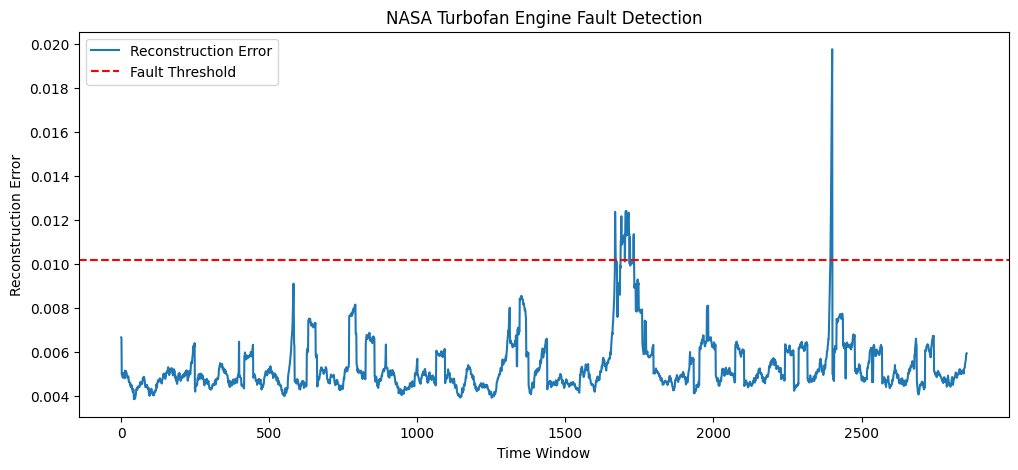

In [19]:
# =====================================================
# STEP 8: DISPLAY FAULT DETECTION RESULTS
# =====================================================

plt.figure(figsize=(12, 5))

plt.plot(test_error, label='Reconstruction Error')

plt.axhline(
    y=threshold,
    color='red',
    linestyle='--',
    label='Fault Threshold'
)

plt.title('NASA Turbofan Engine Fault Detection')
plt.xlabel('Time Window')
plt.ylabel('Reconstruction Error')
plt.legend()
plt.show()

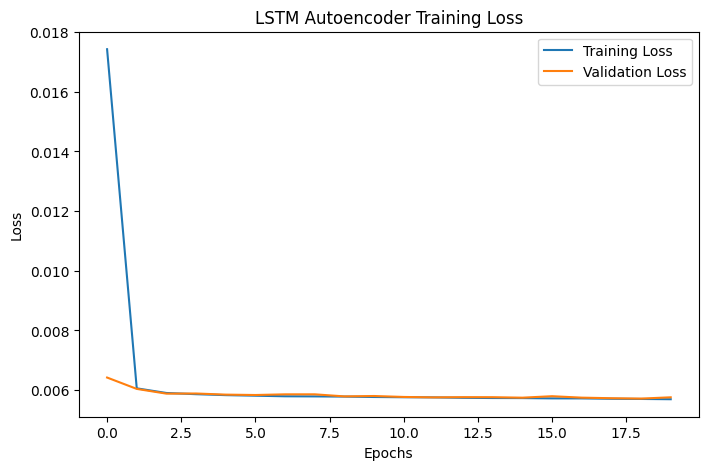

In [20]:
# =====================================================
# STEP 9: PLOT TRAINING LOSS
# =====================================================

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('LSTM Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


In [21]:
# Display detected fault status
for i in range(min(10, len(anomalies))):

    if anomalies[i] == 1:
        print("Window", i, ": Fault Detected")
    else:
        print("Window", i, ": Healthy")

Window 0 : Healthy
Window 1 : Healthy
Window 2 : Healthy
Window 3 : Healthy
Window 4 : Healthy
Window 5 : Healthy
Window 6 : Healthy
Window 7 : Healthy
Window 8 : Healthy
Window 9 : Healthy
